# Предобработка и классификация текста

## Вариант B

Цель работы — собрать пайплайн предобработки текста и обучить классификатор.

Используется файл players.csv:
- текстовый признак — playstyles;
- целевая переменная — группа позиции игрока.

Этапы работы:
1. Очистка и токенизация текста.
2. Разбиение на train и test.
3. Векторизация TF-IDF.
4. Обучение классификатора.
5. Оценка качества.
6. Анализ пяти ошибок модели.

Особенность данных: playstyles содержит короткие списки игровых терминов,
а не связные тексты.

In [1]:
from pathlib import Path
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import (
    ENGLISH_STOP_WORDS,
    TfidfVectorizer,
)
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

pd.set_option("display.max_colwidth", 160)

print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)

Python: 3.14.7
scikit-learn: 1.9.1


In [2]:
# Поддерживаем запуск из корня проекта и из папки notebooks.
possible_paths = [
    Path("../data/players.csv"),
    Path("data/players.csv"),
]

data_path = next(
    (path for path in possible_paths if path.is_file()),
    None,
)

if data_path is None:
    raise FileNotFoundError(
        "Файл не найден. Положи players.csv в папку data."
    )

df = pd.read_csv(data_path)

print("Размер исходных данных:", df.shape)
print("Заполнено playstyles:", df["playstyles"].notna().sum())

display(
    df[["player_id", "position", "playstyles"]].head()
)

Размер исходных данных: (19789, 60)
Заполнено playstyles: 8051


,player_id,position,playstyles
0,227203,CM,"Finesse Shot, Gamechanger, Tiki Taka, Inventive, Technical, First Touch, Incisive Pass+"
1,231747,ST,"Finesse Shot, Acrobatic, Low Driven Shot, Gamechanger, Rapid, First Touch, Quick Step+"
2,239085,ST,"Chip Shot, Power Shot, Precision Header, Acrobatic, Gamechanger, Enforcer, Low Driven Shot+"
3,192119,GK,"Far Throw, Far Reach, Rush Out+"
4,202126,ST,"Precision Header, Low Driven Shot, Gamechanger, Long Ball Pass, First Touch, Press Proven, Finesse Shot+"


In [3]:
position_groups = {
    "GK": "Goalkeeper",

    "CB": "Defender",
    "LB": "Defender",
    "RB": "Defender",

    "CDM": "Midfielder",
    "CM": "Midfielder",
    "CAM": "Midfielder",
    "LM": "Midfielder",
    "RM": "Midfielder",

    "ST": "Forward",
    "LW": "Forward",
    "RW": "Forward",
}

# Убираем строки без текста.
nonempty = (
    df["playstyles"].notna()
    & df["playstyles"].fillna("").str.strip().ne("")
)

data = df.loc[nonempty].copy()

# Создаём целевой класс.
data["target"] = data["position"].map(position_groups)

if data["target"].isna().any():
    raise ValueError(
        "Есть позиции, которых нет в словаре position_groups."
    )

if data["player_id"].isna().any():
    raise ValueError("Есть игроки без player_id.")

if data["player_id"].duplicated().any():
    raise ValueError(
        "Есть повторяющиеся игроки. Нужна групповая разбивка."
    )

print("Используем строк:", len(data))
print("Исключено строк без текста:", len(df) - len(data))

display(
    data["target"]
    .value_counts()
    .rename_axis("Класс")
    .to_frame("Количество")
)

Используем строк: 8051
Исключено строк без текста: 11738


,Количество
Класс,
Midfielder,3057
Defender,2769
Forward,1472
Goalkeeper,753


Строки с пустым playstyles исключены, поскольку они не содержат текста
для классификации.

Поэтому полученные метрики относятся только к игрокам
с заполненными игровыми стилями.

Позиции объединены в четыре группы. Группировка является выбранным
определением учебной задачи: например, LM/RM относятся к полузащитникам,
а LW/RW — к нападающим.

In [4]:
train_df, test_df = train_test_split(
    data,
    test_size=0.2,
    random_state=42,
    stratify=data["target"],
)

X_train = train_df["playstyles"]
X_test = test_df["playstyles"]

y_train = train_df["target"]
y_test = test_df["target"]

# Проверяем, что один игрок не попал в обе части.
assert set(train_df["player_id"]).isdisjoint(
    set(test_df["player_id"])
)

print("Train:", len(X_train))
print("Test:", len(X_test))

display(
    pd.DataFrame({
        "Train": y_train.value_counts(),
        "Test": y_test.value_counts(),
    })
)

Train: 6440
Test: 1611


,Train,Test
target,,
Midfielder,2445,612
Defender,2215,554
Forward,1178,294
Goalkeeper,602,151


In [5]:
# Сохраняем отрицания и значимые части названий стилей.
PROTECTED_WORDS = {
    "no",
    "not",
    "nor",
    "never",
    "without",
    "first",
    "out",
}

STOP_WORDS = set(ENGLISH_STOP_WORDS) - PROTECTED_WORDS


def tokenize_text(text):
    if pd.isna(text):
        return []

    # 1. Нижний регистр.
    text = str(text).lower()

    # 2. Пунктуацию и цифры заменяем пробелами.
    # Данные содержат английские названия стилей.
    text = re.sub(r"[^a-z\s]", " ", text)

    # 3. Токенизация: разделение на слова.
    tokens = text.split()

    # 4. Удаление стоп-слов.
    tokens = [
        word
        for word in tokens
        if word not in STOP_WORDS
    ]

    return tokens


def clean_text(text):
    return " ".join(tokenize_text(text))


def clean_corpus(texts):
    return [clean_text(text) for text in texts]

In [6]:
example = "The FIRST Touch+, Rush Out! NOT 123 a shot."

print("Исходный текст:", example)
print("Токены:", tokenize_text(example))
print("Очищенный текст:", clean_text(example))

preview = X_train.head(5).to_frame("Исходный текст")

preview["Очищенный текст"] = (
    preview["Исходный текст"].map(clean_text)
)

preview["Токены"] = (
    preview["Исходный текст"].map(tokenize_text)
)

display(preview)

Исходный текст: The FIRST Touch+, Rush Out! NOT 123 a shot.
Токены: ['first', 'touch', 'rush', 'out', 'not', 'shot']
Очищенный текст: first touch rush out not shot


,Исходный текст,Очищенный текст,Токены
7225,"Long Ball Pass, Deflector",long ball pass deflector,"[long, ball, pass, deflector]"
4499,"Long Ball Pass, Technical, Relentless",long ball pass technical relentless,"[long, ball, pass, technical, relentless]"
9194,Footwork,footwork,[footwork]
13453,Rapid,rapid,[rapid]
251,"Power Shot, Precision Header, Gamechanger, Enforcer",power shot precision header gamechanger enforcer,"[power, shot, precision, header, gamechanger, enforcer]"


In [7]:
train_words = set(
    " ".join(
        re.sub(r"[^a-z\s]", " ", text.lower())
        for text in X_train
    ).split()
)

print(
    "Слова train из стандартного списка стоп-слов:",
    sorted(train_words & set(ENGLISH_STOP_WORDS)),
)

print(
    "Слова train, которые реально удаляются:",
    sorted(train_words & STOP_WORDS),
)

Слова train из стандартного списка стоп-слов: ['first', 'out']
Слова train, которые реально удаляются: []


Использован английский список стоп-слов.

Из списка исключены отрицания no/not/nor/never/without,
а также first и out, поскольку они входят в названия
First Touch и Rush Out.

Проверка стоп-слов выполнена на train.

Стемминг и лемматизация не применяются: тексты состоят из фиксированных
названий игровых стилей, поэтому дополнительное сокращение слов
не требуется.

При удалении пунктуации знак + исчезает. Это объединяет обычный
и усиленный вариант стиля и является ограничением предобработки.

In [8]:
model = Pipeline([
    (
        "clean",
        FunctionTransformer(
            clean_corpus,
            validate=False,
        ),
    ),
    (
        "tfidf",
        TfidfVectorizer(
            tokenizer=str.split,
            token_pattern=None,
            lowercase=False,
            min_df=2,
            max_df=0.95,
            max_features=3000,
            ngram_range=(1, 2),
        ),
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            C=1.0,
            random_state=42,
        ),
    ),
])

# Обучаем только на тренировочных данных.
model.fit(X_train, y_train)

# Получаем предсказания для тестовых данных.
y_pred = model.predict(X_test)

print("Модель обучена.")

Модель обучена.


In [9]:
# Выполняем очистку и векторизацию без классификатора.
train_matrix = model[:-1].transform(X_train)
test_matrix = model[:-1].transform(X_test)

print("Размер train:", train_matrix.shape)
print("Размер test:", test_matrix.shape)
print(
    "Размерность признакового пространства:",
    train_matrix.shape[1],
)

assert train_matrix.shape[1] == test_matrix.shape[1]

print(
    "Первые признаки:",
    model["tfidf"].get_feature_names_out()[:20].tolist(),
)

print(
    "Тестовых текстов с нулевым вектором:",
    int((test_matrix.getnnz(axis=1) == 0).sum()),
)

Размер train: (6440, 354)
Размер test: (1611, 354)
Размерность признакового пространства: 354
Первые признаки: ['acrobatic', 'acrobatic aerial', 'acrobatic enforcer', 'acrobatic first', 'acrobatic gamechanger', 'acrobatic incisive', 'acrobatic inventive', 'acrobatic low', 'acrobatic press', 'acrobatic rapid', 'acrobatic technical', 'acrobatic trickster', 'acrobatic whipped', 'aerial', 'aerial fortress', 'anticipate', 'anticipate aerial', 'anticipate bruiser', 'anticipate enforcer', 'anticipate first']
Тестовых текстов с нулевым вектором: 0


Размерность признакового пространства TF-IDF — 354.

Train и test имеют одинаковое количество признаков.
Векторизатор обучен только на train, а test преобразован
с уже обученным словарём и значениями IDF.

Таким образом, утечки данных через обучение векторизатора
на тестовой выборке нет.

In [10]:
accuracy = accuracy_score(y_test, y_pred)

macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro",
)

print(f"Accuracy: {accuracy:.4f}")
print(f"Macro-F1: {macro_f1:.4f}")

print(
    classification_report(
        y_test,
        y_pred,
        digits=4,
        zero_division=0,
    )
)

Accuracy: 0.7349
Macro-F1: 0.7661
              precision    recall  f1-score   support

    Defender     0.7822    0.8556    0.8172       554
     Forward     0.5306    0.7075    0.6064       294
  Goalkeeper     1.0000    0.9603    0.9797       151
  Midfielder     0.7628    0.5833    0.6611       612

    accuracy                         0.7349      1611
   macro avg     0.7689    0.7767    0.7661      1611
weighted avg     0.7493    0.7349    0.7347      1611



Основная метрика — macro-F1, поскольку классы несбалансированы.

Macro-F1 усредняет F1 каждого класса с одинаковым весом,
поэтому качество на менее многочисленном классе вратарей
также учитывается.

Дополнительно рассчитаны accuracy и precision, recall, F1
для каждого класса.

Accuracy составляет примерно 73,49%, macro-F1 — 0,7661.

In [11]:
baseline = DummyClassifier(
    strategy="most_frequent"
)

baseline.fit(
    np.zeros((len(y_train), 1)),
    y_train,
)

baseline_pred = baseline.predict(
    np.zeros((len(y_test), 1))
)

comparison = pd.DataFrame([
    {
        "Модель": "Самый частый класс",
        "Accuracy": accuracy_score(
            y_test,
            baseline_pred,
        ),
        "Macro-F1": f1_score(
            y_test,
            baseline_pred,
            average="macro",
        ),
    },
    {
        "Модель": "TF-IDF + LogisticRegression",
        "Accuracy": accuracy,
        "Macro-F1": macro_f1,
    },
])

display(comparison.round(4))

,Модель,Accuracy,Macro-F1
0,Самый частый класс,0.3799,0.1377
1,TF-IDF + LogisticRegression,0.7349,0.7661


Модель на текстовых признаках заметно превосходит классификатор,
который всегда выбирает самый частый класс.

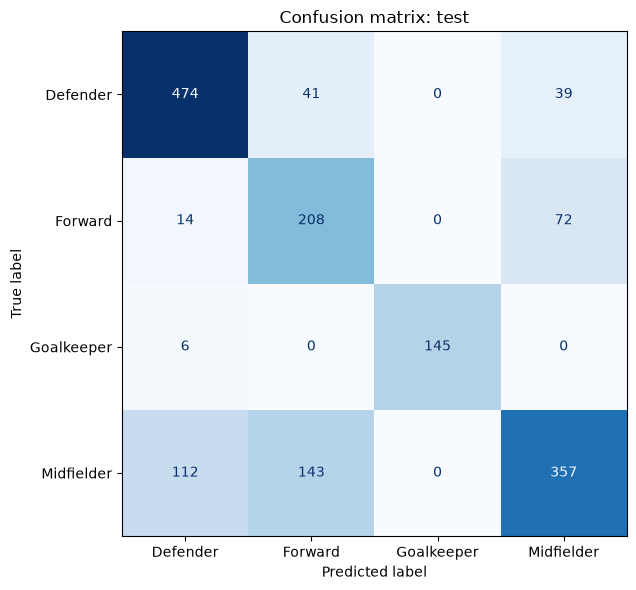

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=model["classifier"].classes_,
    cmap="Blues",
    colorbar=False,
    ax=ax,
)

ax.set_title("Confusion matrix: test")

plt.tight_layout()
plt.show()

In [13]:
errors = test_df[
    [
        "player_id",
        "first_name",
        "last_name",
        "position",
        "playstyles",
        "target",
    ]
].copy()

errors["predicted"] = y_pred

errors = errors.loc[
    errors["target"] != errors["predicted"]
].copy()

errors["cleaned_text"] = (
    errors["playstyles"].map(clean_text)
)

print("Количество ошибок:", len(errors))

display(errors.head(10))

Количество ошибок: 427


,player_id,first_name,last_name,position,playstyles,target,predicted,cleaned_text
6288,270328,Donat,Rrudhani,CAM,Finesse Shot,Midfielder,Forward,finesse shot
11360,75156,Antonio,Fernández Casino,RW,Inventive,Forward,Midfielder,inventive
1514,246871,Enzo,Barrenechea,CDM,"Long Ball Pass, Intercept",Midfielder,Defender,long ball pass intercept
2076,276862,Kaja,Korošec,CDM,Aerial Fortress,Midfielder,Defender,aerial fortress
11770,230972,Adriel,Ba Loua,RM,"Technical, Quick Step",Midfielder,Forward,technical quick step
2301,243646,Benjamin,Nygren,CM,"Finesse Shot, Low Driven Shot, Incisive Pass",Midfielder,Forward,finesse shot low driven shot incisive pass
8110,237511,Alfons,Sampsted,RB,"Anticipate, Relentless",Defender,Midfielder,anticipate relentless
13311,262840,Lukas,Kunze,CM,Bruiser,Midfielder,Defender,bruiser
2543,277426,Carlos Roberto,Forbs Borges,RM,"Rapid, Trickster, Quick Step",Midfielder,Forward,rapid trickster quick step
10704,245021,Mamadou,Loum,CDM,"Precision Header, Long Ball Pass",Midfielder,Defender,precision header long ball pass


In [16]:
selected_ids = [
    270328,
    75156,
    246871,
    238409,
    227050,
]

hypotheses = {
    270328: (
        "Указан только Finesse Shot — стиль удара. "
        "Он может ассоциироваться с нападающими, "
        "но реальная позиция игрока CAM относится "
        "к полузащитникам."
    ),
    75156: (
        "Единственный стиль Inventive может встречаться "
        "у созидательных полузащитников. "
        "По одному общему стилю трудно определить "
        "позицию RW."
    ),
    246871: (
        "Long Ball Pass и Intercept описывают "
        "длинные передачи и перехваты. "
        "Такие навыки встречаются и у опорных "
        "полузащитников, и у защитников."
    ),
    238409: (
        "Rapid описывает скорость. "
        "Скоростной фланговый защитник может "
        "по этому единственному стилю выглядеть "
        "как нападающий."
    ),
    227050: (
        "У вратаря указан только Long Ball Pass. "
        "В тексте нет специфичных вратарских стилей, "
        "поэтому модель выбрала защитника."
    ),
}

indexed_errors = errors.set_index(
    "player_id",
    drop=False,
)

missing_ids = [
    player_id
    for player_id in selected_ids
    if player_id not in indexed_errors.index
]

if missing_ids:
    raise ValueError(
        f"Эти игроки не являются ошибками текущей модели: "
        f"{missing_ids}. Выбери другие примеры из errors."
    )

five_errors = indexed_errors.loc[
    selected_ids
].copy()

five_errors["hypothesis"] = [
    hypotheses[player_id]
    for player_id in selected_ids
]

for number, (_, row) in enumerate(
    five_errors.iterrows(),
    start=1,
):
    print(
        f"\nОшибка {number}: "
        f"{row['first_name']} {row['last_name']}"
    )
    print("Текст:", row["playstyles"])
    print("После очистки:", row["cleaned_text"])
    print("Реальный класс:", row["target"])
    print("Предсказанный класс:", row["predicted"])
    print("Гипотеза:", row["hypothesis"])


Ошибка 1: Donat Rrudhani
Текст: Finesse Shot
После очистки: finesse shot
Реальный класс: Midfielder
Предсказанный класс: Forward
Гипотеза: Указан только Finesse Shot — стиль удара. Он может ассоциироваться с нападающими, но реальная позиция игрока CAM относится к полузащитникам.

Ошибка 2: Antonio Fernández Casino
Текст: Inventive
После очистки: inventive
Реальный класс: Forward
Предсказанный класс: Midfielder
Гипотеза: Единственный стиль Inventive может встречаться у созидательных полузащитников. По одному общему стилю трудно определить позицию RW.

Ошибка 3: Enzo Barrenechea
Текст: Long Ball Pass, Intercept
После очистки: long ball pass intercept
Реальный класс: Midfielder
Предсказанный класс: Defender
Гипотеза: Long Ball Pass и Intercept описывают длинные передачи и перехваты. Такие навыки встречаются и у опорных полузащитников, и у защитников.

Ошибка 4: Marlon Fossey
Текст: Rapid
После очистки: rapid
Реальный класс: Defender
Предсказанный класс: Forward
Гипотеза: Rapid описывает 

## Вывод

В работе собран пайплайн предобработки и классификации текстового
поля playstyles из players.csv.

Реализованы:
- приведение текста к нижнему регистру;
- удаление пунктуации и цифр;
- токенизация;
- удаление английских стоп-слов.

Сохранены отрицания и значимые части названий first/out.
Стемминг и лемматизация не применялись, поскольку тексты состоят
из фиксированных игровых терминов.

Данные разделены на train и test до обучения векторизатора.
TF-IDF обучен только на train. Использованы min_df=2, max_df=0.95,
униграммы и биграммы. Размерность признакового пространства — 354.

Обучена логистическая регрессия с балансировкой весов классов.
Accuracy составила примерно 0,7349, macro-F1 — 0,7661.

Основной метрикой выбрана macro-F1 из-за дисбаланса классов.
Модель превосходит предсказание самого частого класса.

Проанализированы пять ошибочных предсказаний. Возможные причины:
короткие тексты, общие стили разных позиций и отсутствие
специфичных признаков нужного класса.

Ограничения:
- качество оценивается только на игроках с заполненным playstyles;
- удаление знака + приводит к потере информации об усиленном стиле;
- результат на списках терминов нельзя автоматически переносить
  на отзывы, новости и другие связные тексты.

Для дальнейшего улучшения можно сохранить усиленные стили
как отдельные токены и подбирать параметры на кросс-валидации train.